
<div class="alert alert-block alert-success">
<b> Ex - 1 : </b> Train a deep neural network for an image classification task.
</div>

<hr style="border-top: 3px dotted #bbb;">


<details>
<summary><b>👉 Click here to reveal the hidden code solution</b></summary>

```python
# Your hidden code block sits neatly inside here
import tensorflow as tf
print("Hidden code executed!")
```
</details>


In [8]:
import numpy as np
import os

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report,confusion_matrix

import tensorflow as tf
from tensorflow.keras.preprocessing.image import load_img, img_to_array

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten, Dropout
from tensorflow.keras.utils import to_categorical # type: ignore
import matplotlib.pyplot as plt

### Task 1: Load the Dataset

In [9]:
import os
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing.image import load_img, img_to_array
from PIL import UnidentifiedImageError

def load_images_from_folder(folder_path, image_size=(128, 128)):
    images = []
    labels = []
    class_names = sorted(os.listdir(folder_path))
    
    for label, class_name in enumerate(class_names):         
        class_path = os.path.join(folder_path, class_name)
        if not os.path.isdir(class_path):
            continue
            
        for filename in os.listdir(class_path):             
            img_path = os.path.join(class_path, filename)
            try:
                img = load_img(img_path, target_size=image_size)
                img_array = img_to_array(img) / 255.0  # Normalize pixel values
                images.append(img_array)
                labels.append(label)
            except UnidentifiedImageError:
                continue 
                
    return np.array(images), np.array(labels), class_names



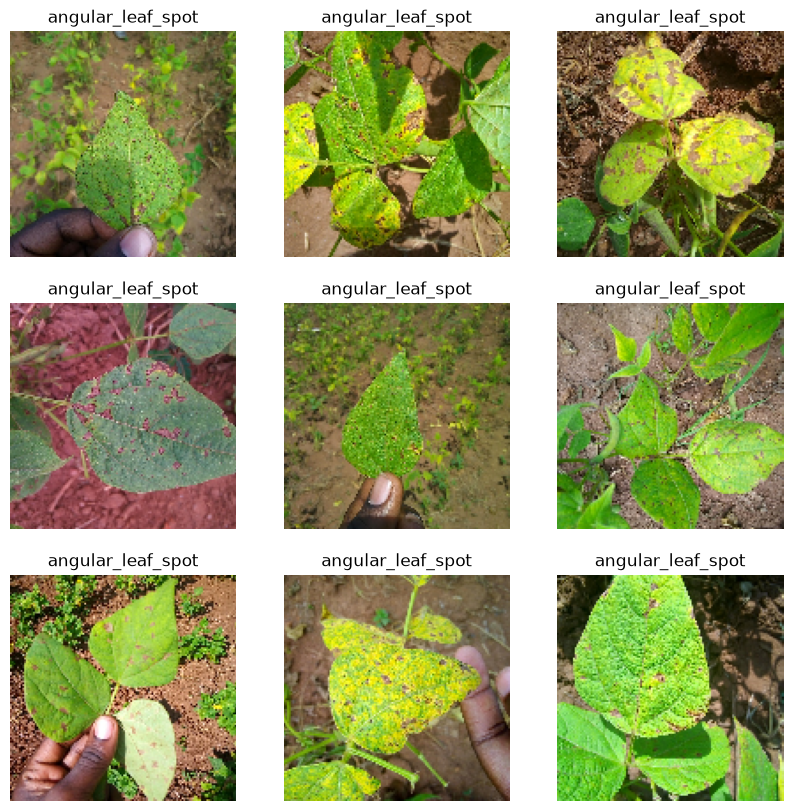

Loaded 990 images of size (128, 128, 3).


In [10]:
# Load the dataset

# ==========================================
# Load the dataset under path function call
# ==========================================
dataset_path = r"E:\Z_Arise\DL\Bean_Dataset"
X, y, class_names = load_images_from_folder(dataset_path, image_size=(128, 128))

# Display a sample batch of 9 images
plt.figure(figsize=(10, 10))
for i in range(9):
    plt.subplot(3, 3, i + 1)
    plt.imshow(X[i])  
    plt.title(class_names[y[i]])
    plt.axis('off')
plt.show()

# Print shapes and info
print(f"Loaded {X.shape[0]} images of size {X.shape[1:]}.")


## Task 2: Split the Dataset

In [11]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2, random_state=42)

print(f" Processed Training Data : {X_train.shape[0]}")
print(f" Processed Test Data : {X_test.shape[0]}")

y_train_cat = to_categorical(y_train)
y_test_cat = to_categorical(y_test)

 Processed Training Data : 792
 Processed Test Data : 198


## Task 3: Data Preprocessing

In [12]:
# # Flatten the image data to feed into the DNN
X_train_flat = X_train.reshape(X_train.shape[0],-1)
X_test_flat = X_test.reshape(X_test.shape[0],-1)

## Convert lables to one-hot encoding
num_classes = len(class_names)
y_train = to_categorical(y_train, num_classes)
y_test = to_categorical(y_test, num_classes)

print(f" Processed Training Data : {X_train_flat.shape[0]}")
print(f" Processed Test Data : {X_test_flat.shape[0]}")


 Processed Training Data : 792
 Processed Test Data : 198


## Task 4 : Design the Deep Neural Network

In [13]:
model = Sequential([
    Dense(512, activation='relu', input_shape=(X_train_flat.shape[1],)),
    Dense(256, activation='relu'),
    Dense(num_classes, activation='softmax')
])

e:\Z_Arise\rika_dl_env\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


## Task 5: Compile the Model

In [14]:
model.compile(
    optimizer = 'adam',
    loss = 'sparse_categorical_crossentropy',
    metrics = ['accuracy']
)

## Task 6: Train the Model

In [15]:
history = model.fit(
    X_train_flat, y_train, 
    epochs=10,
    validation_split=0.2,
    batch_size=32
)

Epoch 1/10


ValueError: Argument `output` must have rank (ndim) `target.ndim - 1`. Received: target.shape=(None, 4), output.shape=(None, 4)

## Task 7: Evaluate the Model

In [ ]:
test_loss, test_accuracy = model.evaluate(X_test_flat, y_test)
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.5758 - loss: 1.1681
Test Accuracy: 57.58%


## Task 8: Generate Predictions

In [ ]:
y_pred = np.argmax(model.predict(X_test_flat), axis=-1)
y_true = np.argmax(y_test, axis=-1)

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step


## Task 9: Performance Evaluation

In [ ]:
print("Classification Report:")
print(classification_report(y_true, y_pred, target_names=class_names))
print("Confusion Matrix:")
print(confusion_matrix(y_true, y_pred))

Classification Report:


InvalidParameterError: The 'y_true' parameter of classification_report must be an array-like or a sparse array or matrix. Got np.int64(14) instead.

## Task 10: Visualize the Training Process

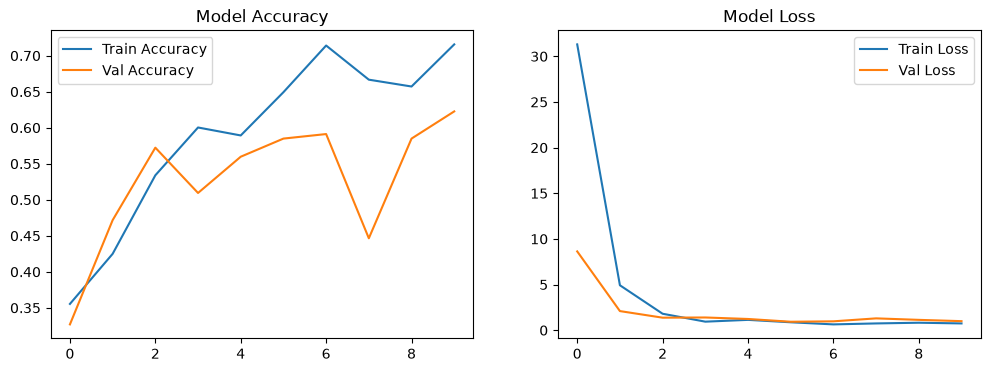

In [ ]:
# Plot the training history
def plot_history(history):     
    plt.figure(figsize=(12, 4))
    # Plot accuracy
    plt.subplot(1, 2, 1)
    plt.plot(history.history['accuracy'], label='Train Accuracy')
    plt.plot(history.history['val_accuracy'], label='Val Accuracy')
    plt.title('Model Accuracy')
    plt.legend()
    # Plot loss
    plt.subplot(1, 2, 2)
    plt.plot(history.history['loss'], label='Train Loss')
    plt.plot(history.history['val_loss'], label='Val Loss')
    plt.title('Model Loss')
    plt.legend()
    plt.show()
plot_history(history)